# Predicting Workout Burnout and Overtraining Risk Using Fitbit Activity and Recovery Data

**Group 10**

## Project Overview

The purpose of this project is to explore and prepare Fitbit activity, intensity, and sleep data for the future development of a machine learning model that identifies sustained declines in exercise behavior.

The available datasets do not contain a direct measure of burnout, fatigue, injury, motivation, or overtraining. Therefore, this project proposes using a sustained reduction in daily activity as a behavioral proxy for potential workout burnout risk.

This Part 1 notebook documents:

1. The project objective and assumptions
2. The structure and quality of the source datasets
3. Data cleaning and transformation
4. Aggregation and merging of the datasets
5. Exploratory data analysis and visualization
6. Preliminary feature exploration
7. Preparation for future target creation and model development

## Business Objective and Analytical Objective

*Business Objective:* Explore whether Fitbit activity and recovery patterns can be used to identify sustained declines in exercise behavior that may signal elevated workout burnout or overtraining risk.

*Analytical Objective:* Clean, combine, and evaluate daily activity, hourly intensity, and sleep data; identify relevant behavioral features; and prepare the data for the future development of a burnout-risk classification model.

Because the available data do not contain a direct burnout diagnosis or self-reported burnout measure, this project treats burnout as a behavioral proxy rather than a medical outcome.

### Research Questions

1. Which activity, intensity, and recovery measures may be useful for identifying sustained declines in exercise behavior?
2. How do activity patterns vary within and between participants over time?
3. Is lower or inconsistent sleep associated with changes in subsequent activity?
4. Which participants display the greatest variability or decline in activity?
5. How could a reproducible behavioral burnout-risk proxy be constructed from the available data?
6. What additional data would be required to validate the proxy as a true measure of burnout?

# Get The Data 
1. Import packages
2. Import Data from: https://www.kaggle.com/code/devraai/bellabeat-activity-data-analysis-prediction
3. Inspect the  Data Size and Type
4. Create a test set **(Done After Data Wrangled)**

## Import the Source Data

Three Fitbit datasets are used in this project:

| Dataset | Level of Measurement | Purpose |
|---|---|---|
| Daily activity | Participant-day | Provides steps, distance, active minutes, sedentary minutes, and calories |
| Hourly intensities | Participant-hour | Provides hourly total and average activity intensity |
| Sleep | Participant-day | Provides sleep duration and time in bed |

The datasets will ultimately be combined using participant ID and date. Because intensity is recorded hourly, it must first be aggregated to the participant-day level.

## Import required Packages

In [103]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import pyplot
import seaborn as sns
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

%matplotlib inline
sns.set()
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## Import Data
1. Pull in CSV Files
2. View Data

#### Pull in Data

In [104]:
base_url = "../data/"  # local copy of the cleaned Fitbit files

df_activity = pd.read_csv(base_url + "Daily_activity_clean.csv")
df_intensities = pd.read_csv(base_url + "hourly_intensities_clean.csv")
df_sleep = pd.read_csv(base_url + "Sleep_clean.csv")

print("Datasets loaded successfully.")
print("Daily activity shape:", df_activity.shape)
print("Hourly intensity shape:", df_intensities.shape)
print("Sleep shape:", df_sleep.shape)

Datasets loaded successfully.
Daily activity shape: (1373, 16)
Hourly intensity shape: (46008, 4)
Sleep shape: (410, 5)


#### View Data

In [105]:
df_activity.head(10)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,rn
0,2320127002,2016-04-01,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1324,1
1,4020332650,2016-04-19,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,1
2,4057192912,2016-04-07,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,1,1439,1778,1
3,8792009665,2016-04-18,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1688,1
4,6117666160,2016-04-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,1
5,4020332650,2016-04-24,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,1
6,4020332650,2016-04-28,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,1
7,4388161847,2016-04-03,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1878,1
8,6775888955,2016-04-21,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1841,1
9,8583815059,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,1


In [106]:
df_intensities.head(10)

,Id,Activity_Hour,Total_Intensity,Average_Intensity
0,1503960366,2016-04-20 05:00:00 UTC,0,0.0
1,1503960366,2016-03-12 06:00:00 UTC,0,0.0
2,1503960366,2016-04-10 09:00:00 UTC,0,0.0
3,1503960366,2016-05-10 03:00:00 UTC,0,0.0
4,1503960366,2016-03-29 22:00:00 UTC,0,0.0
5,1503960366,2016-04-20 02:00:00 UTC,0,0.0
6,1503960366,2016-03-26 07:00:00 UTC,0,0.0
7,1503960366,2016-04-30 07:00:00 UTC,0,0.0
8,1503960366,2016-04-28 00:00:00 UTC,0,0.0
9,1503960366,2016-04-07 05:00:00 UTC,0,0.0


In [107]:
df_sleep.head(10)

,Id,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed
0,1503960366,2016-05-08 00:00:00 UTC,1,594,611
1,1503960366,2016-04-25 00:00:00 UTC,1,277,323
2,1503960366,2016-04-17 00:00:00 UTC,1,700,712
3,1503960366,2016-05-11 00:00:00 UTC,1,285,306
4,1503960366,2016-04-28 00:00:00 UTC,1,366,393
5,1503960366,2016-05-10 00:00:00 UTC,1,383,403
6,1503960366,2016-04-24 00:00:00 UTC,1,430,449
7,1503960366,2016-04-12 00:00:00 UTC,1,327,346
8,1503960366,2016-04-30 00:00:00 UTC,1,404,425
9,1503960366,2016-05-07 00:00:00 UTC,1,331,349


### Initial Observation

The individual source files do not show missing values within their existing records. However, this does not mean the combined dataset will be complete.

The datasets differ in both coverage and granularity:

- Daily activity contains records for 35 participants.
- Hourly intensity also contains records for 35 participants.
- Sleep contains records for only 24 participants.
- Sleep and activity records are not available for every participant-date combination.

Additional data-quality checks are therefore required before the files are merged.

## Initial Data Exploration

Before transforming the data, the following checks are performed:

1. Review dataset dimensions and descriptive statistics
2. Inspect data types
3. Count unique participants
4. Review date coverage
5. Identify missing or incomplete coverage
6. Check for constant or redundant variables
7. Identify potential candidate predictors

### Descriptive Statistics

In [108]:
df_sleep.describe()

,Id,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed
count,4.100000e+02,410.000000,410.000000,410.000000
mean,4.994963e+09,1.119512,419.173171,458.482927
std,2.060863e+09,0.346636,118.635918,127.455140
min,1.503960e+09,1.000000,58.000000,61.000000
25%,3.977334e+09,1.000000,361.000000,403.750000
50%,4.702922e+09,1.000000,432.500000,463.000000
75%,6.962181e+09,1.000000,490.000000,526.000000
max,8.792010e+09,3.000000,796.000000,961.000000


#### Sleep Data Interpretation

The sleep dataset contains 410 records from 24 participants, substantially fewer than the activity and intensity datasets.

Among recorded sleep observations:

- Average sleep duration is approximately 419 minutes, or about 7.0 hours.
- Median sleep duration is approximately 433 minutes.
- Recorded sleep ranges from 58 to 796 minutes.
- Average time in bed is approximately 458 minutes, or about 7.6 hours.

The broad range suggests that unusually short and long sleep observations should be examined. More importantly, sleep coverage is incomplete and cannot be assumed for every activity record.


In [109]:
df_intensities.describe()

,Id,Total_Intensity,Average_Intensity
count,4.600800e+04,46008.000000,46008.000000
mean,4.869940e+09,11.422470,0.190375
std,2.421206e+09,20.716827,0.345280
min,1.503960e+09,0.000000,0.000000
25%,2.320127e+09,0.000000,0.000000
50%,4.558610e+09,2.000000,0.033333
75%,6.962181e+09,15.000000,0.250000
max,8.877689e+09,180.000000,3.000000


#### Intensity Data Interpretation

The hourly intensity variables are strongly right-skewed. Their medians are close to zero while the maximum values are substantially higher, indicating that most recorded hours contain little activity and a smaller number contain periods of high activity.

Because the project analyzes daily behavior, these hourly records will be aggregated by participant and date before merging.


In [110]:
df_activity.describe()

,Id,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,rn
count,1.373000e+03,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.0
mean,4.782326e+09,7377.375091,5.289031,5.261930,0.128591,1.413146,0.546052,3.238128,0.001733,19.871085,13.603787,188.096140,1001.346686,2294.812090,1.0
std,2.381544e+09,5198.133424,3.987341,3.973439,0.695630,2.622729,0.872581,2.104300,0.007800,31.817631,26.581555,113.095058,304.168197,725.526989,0.0
min,1.503960e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
25%,2.320127e+09,3321.000000,2.280000,2.270000,0.000000,0.000000,0.000000,1.730000,0.000000,0.000000,0.000000,117.000000,734.000000,1820.000000,1.0
50%,4.445115e+09,7142.000000,5.030000,5.020000,0.000000,0.120000,0.200000,3.280000,0.000000,2.000000,6.000000,196.000000,1062.000000,2129.000000,1.0
75%,6.962181e+09,10645.000000,7.570000,7.570000,0.000000,1.860000,0.780000,4.710000,0.000000,30.000000,18.000000,263.000000,1246.000000,2781.000000,1.0
max,8.877689e+09,36019.000000,28.030001,28.030001,6.727057,21.920000,6.480000,12.510000,0.110000,210.000000,660.000000,720.000000,1440.000000,4900.000000,1.0


#### Daily Activity Interpretation

The daily activity dataset contains 1,373 participant-day records from 35 users.

Key findings include:

- Participants averaged approximately 7,377 daily steps, with a median of 7,142.
- Daily steps ranged from 0 to 36,019, indicating substantial variation.
- TotalDistance and TrackerDistance have nearly identical descriptive statistics and may be redundant.
- VeryActiveMinutes and FairlyActiveMinutes are right-skewed, with many low-activity days and fewer highly active days.
- SedentaryMinutes are high for many observations.
- Zero-step days require cautious interpretation because they may represent true inactivity, device non-wear, or incomplete synchronization.

The values describe the available sample only and should not be interpreted as representative of all Fitbit users.


### Explore Dtypes

In [111]:
df_intensities.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46008 entries, 0 to 46007
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Id                 46008 non-null  int64  
 1   Activity_Hour      46008 non-null  object 
 2   Total_Intensity    46008 non-null  int64  
 3   Average_Intensity  46008 non-null  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 1.4+ MB


In [112]:
df_activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        1373 non-null   int64  
 1   ActivityDate              1373 non-null   object 
 2   TotalSteps                1373 non-null   int64  
 3   TotalDistance             1373 non-null   float64
 4   TrackerDistance           1373 non-null   float64
 5   LoggedActivitiesDistance  1373 non-null   float64
 6   VeryActiveDistance        1373 non-null   float64
 7   ModeratelyActiveDistance  1373 non-null   float64
 8   LightActiveDistance       1373 non-null   float64
 9   SedentaryActiveDistance   1373 non-null   float64
 10  VeryActiveMinutes         1373 non-null   int64  
 11  FairlyActiveMinutes       1373 non-null   int64  
 12  LightlyActiveMinutes      1373 non-null   int64  
 13  SedentaryMinutes          1373 non-null   int64  
 14  Calories

In [113]:
df_sleep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Id                    410 non-null    int64 
 1   Sleep_Day             410 non-null    object
 2   Total_Sleep_Records   410 non-null    int64 
 3   Total_Minutes_Asleep  410 non-null    int64 
 4   Total_Time_In_Bed     410 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 16.1+ KB


### Explore unique Values and Counts

#### Confirm users are unique

In [114]:
df_activity['Id'].nunique()

35

In [115]:
df_intensities['Id'].nunique()

35

In [116]:
df_sleep['Id'].nunique()

24

### Participant Coverage Interpretation

Daily activity and hourly intensity data each contain 35 unique participants. Sleep data contain only 24 participants, meaning 11 activity participants do not have any sleep records in the sleep dataset.

The reason for the missing sleep coverage cannot be determined from the available data. It could reflect device settings, non-wear, synchronization behavior, or differences in data collection. Therefore, the analysis should not state a specific cause.

A left join will be used so that all daily activity records are retained. A separate indicator will identify records with observed sleep data.

#### Check Constant and Zero-Dominated Variables

The rn variable is reviewed to determine whether it contains useful information. Selected activity variables are also reviewed for a high proportion of zero values.

In [117]:
df_activity['rn'].nunique()

1

In [118]:
zero_share = (
    df_activity[
        [
            'LoggedActivitiesDistance',
            'VeryActiveDistance',
            'ModeratelyActiveDistance',
            'LightActiveDistance'
        ]
    ]
    .eq(0)
    .mean()
    .sort_values(ascending=False)
)

print("Proportion of zero values:")
display(zero_share)

Proportion of zero values:


LoggedActivitiesDistance    0.960670
VeryActiveDistance          0.465404
ModeratelyActiveDistance    0.433358
LightActiveDistance         0.112163
dtype: float64

The rn field contains only one unique value and does not provide useful analytical information. Zero values in the activity variables are retained because they may represent legitimate low-activity days, device non-wear, or incomplete synchronization.

#### Explore Distinct Values in Date and Datetime values

In [119]:
df_activity['ActivityDate'].value_counts()

ActivityDate
2016-04-04    35
2016-04-03    35
2016-04-05    35
2016-04-02    35
2016-04-01    34
              ..
2016-03-15     2
2016-03-17     2
2016-03-12     2
2016-03-13     2
2016-03-23     2
Name: count, Length: 62, dtype: int64

In [120]:
df_sleep['Sleep_Day'].value_counts()

Sleep_Day
2016-04-15 00:00:00 UTC    17
2016-04-28 00:00:00 UTC    16
2016-05-01 00:00:00 UTC    16
2016-04-21 00:00:00 UTC    15
2016-04-29 00:00:00 UTC    15
2016-04-30 00:00:00 UTC    15
2016-04-20 00:00:00 UTC    15
2016-04-23 00:00:00 UTC    15
2016-04-19 00:00:00 UTC    14
2016-04-16 00:00:00 UTC    14
2016-04-27 00:00:00 UTC    14
2016-04-13 00:00:00 UTC    14
2016-05-08 00:00:00 UTC    14
2016-04-26 00:00:00 UTC    14
2016-05-07 00:00:00 UTC    13
2016-04-12 00:00:00 UTC    13
2016-04-24 00:00:00 UTC    13
2016-05-02 00:00:00 UTC    13
2016-04-22 00:00:00 UTC    13
2016-04-14 00:00:00 UTC    13
2016-05-10 00:00:00 UTC    12
2016-04-17 00:00:00 UTC    12
2016-05-04 00:00:00 UTC    12
2016-05-06 00:00:00 UTC    12
2016-05-03 00:00:00 UTC    12
2016-05-05 00:00:00 UTC    12
2016-04-25 00:00:00 UTC    12
2016-05-09 00:00:00 UTC    11
2016-05-11 00:00:00 UTC    11
2016-04-18 00:00:00 UTC    10
2016-05-12 00:00:00 UTC     8
Name: count, dtype: int64

## Initial Data Cleaning

The first cleaning stage prepares the individual source files for aggregation and merging.

The following steps are completed:

1. Remove the `rn` field because it contains only one unique value.
2. Convert activity and sleep date fields to datetime formats.
3. Convert the hourly activity timestamp to datetime.
4. Check each source dataset for duplicate rows.
5. Confirm that date fields are compatible before merging.

In [121]:
# Drop rn column
df_activity = df_activity.drop(columns=['rn'])

In [122]:
df_activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        1373 non-null   int64  
 1   ActivityDate              1373 non-null   object 
 2   TotalSteps                1373 non-null   int64  
 3   TotalDistance             1373 non-null   float64
 4   TrackerDistance           1373 non-null   float64
 5   LoggedActivitiesDistance  1373 non-null   float64
 6   VeryActiveDistance        1373 non-null   float64
 7   ModeratelyActiveDistance  1373 non-null   float64
 8   LightActiveDistance       1373 non-null   float64
 9   SedentaryActiveDistance   1373 non-null   float64
 10  VeryActiveMinutes         1373 non-null   int64  
 11  FairlyActiveMinutes       1373 non-null   int64  
 12  LightlyActiveMinutes      1373 non-null   int64  
 13  SedentaryMinutes          1373 non-null   int64  
 14  Calories

In [123]:
# Review Dtypes and convert as needed
print(df_intensities['Activity_Hour'].dtype)
print(df_sleep['Sleep_Day'].dtype)
print(df_intensities['Activity_Hour'].head())
print(df_sleep['Sleep_Day'].head())

object
object
0    2016-04-20 05:00:00 UTC
1    2016-03-12 06:00:00 UTC
2    2016-04-10 09:00:00 UTC
3    2016-05-10 03:00:00 UTC
4    2016-03-29 22:00:00 UTC
Name: Activity_Hour, dtype: object
0    2016-05-08 00:00:00 UTC
1    2016-04-25 00:00:00 UTC
2    2016-04-17 00:00:00 UTC
3    2016-05-11 00:00:00 UTC
4    2016-04-28 00:00:00 UTC
Name: Sleep_Day, dtype: object


In [124]:
df_sleep['Sleep_Day']=pd.to_datetime(df_sleep['Sleep_Day'].str.replace(' UTC',''))

In [125]:
df_activity['ActivityDate'] = pd.to_datetime(df_activity['ActivityDate'])

In [126]:
df_intensities['Activity_Hour'] = pd.to_datetime(
    df_intensities['Activity_Hour'],
    errors='coerce'
)

In [127]:
print(df_activity['ActivityDate'].dtype)

datetime64[ns]


In [128]:
print(df_sleep['Sleep_Day'].dtype)

datetime64[ns]


In [129]:
# Check for Duplicates 
print("Activity duplicates:",df_activity.duplicated().sum())
print("Intensity duplicates:",df_intensities.duplicated().sum())
print("Sleep duplicates:",df_sleep.duplicated().sum())

Activity duplicates: 0
Intensity duplicates: 0
Sleep duplicates: 0


### Cleaning Results

No fully duplicated rows were identified in the activity, intensity, or sleep datasets.

The `rn` field was removed because it was constant and did not contribute analytical information. Date fields were converted to datetime objects to allow records to be accurately grouped and matched by participant and calendar date.

## Aggregate and Merge the Data

The daily activity dataset is used as the base because it has the broadest participant-day coverage.

1. Sleep data are joined to daily activity using participant ID and date.
2. Hourly intensity records are converted to daily summaries.
3. Daily intensity is then joined to the combined activity and sleep dataset.
4. Left joins are used to retain all daily activity records, even when sleep or intensity information is unavailable.

In [130]:
merged = pd.merge(
    df_activity, 
    df_sleep,
    how='left',
    left_on=['Id', 'ActivityDate'],
    right_on=['Id','Sleep_Day']
)
print("Left join rows:", len(merged))
print("Rows with missing sleep data:", merged['Total_Minutes_Asleep'].isna().sum())

Left join rows: 1373
Rows with missing sleep data: 963


In [131]:
merged.head()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed
0,2320127002,2016-04-01,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1324,NaT,NaN,NaN,NaN
1,4020332650,2016-04-19,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,NaT,NaN,NaN,NaN
2,4057192912,2016-04-07,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,1,1439,1778,NaT,NaN,NaN,NaN
3,8792009665,2016-04-18,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1688,NaT,NaN,NaN,NaN
4,6117666160,2016-04-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,NaT,NaN,NaN,NaN


In [132]:
df_intensities['date'] = df_intensities['Activity_Hour'].dt.date

In [133]:
df_intensities_daily = df_intensities.groupby(['Id','date']).agg(
    Total_Intensity = ('Total_Intensity', 'sum'),
    Average_Intensity = ('Average_Intensity', 'mean')
).reset_index()

In [134]:
df_intensities_daily['date'] = pd.to_datetime(df_intensities_daily['date'])

In [135]:
df_intensities_daily.head()

,Id,date,Total_Intensity,Average_Intensity
0,1503960366,2016-03-12,596,0.413889
1,1503960366,2016-03-13,557,0.386806
2,1503960366,2016-03-14,369,0.256250
3,1503960366,2016-03-15,495,0.343750
4,1503960366,2016-03-16,434,0.301389


In [136]:
df_intensities_daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1935 entries, 0 to 1934
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Id                 1935 non-null   int64         
 1   date               1935 non-null   datetime64[ns]
 2   Total_Intensity    1935 non-null   int64         
 3   Average_Intensity  1935 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 60.6 KB


In [137]:
print("Daily intensity rows:", len(df_intensities_daily))

Daily intensity rows: 1935


In [138]:
df_fitbit = pd.merge(
    merged,
    df_intensities_daily, 
    how='left',
    left_on=['Id', 'ActivityDate'],
    right_on=['Id','date']
)
print("Final merged rows:", len(df_fitbit))
print("Missing intensity data:", df_fitbit['Total_Intensity'].isna().sum())

Final merged rows: 1373
Missing intensity data: 31


# Explore FitBit DF

In [139]:
df_fitbit.head(10)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,...,LightlyActiveMinutes,SedentaryMinutes,Calories,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed,date,Total_Intensity,Average_Intensity
0,2320127002,2016-04-01,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1324,NaT,NaN,NaN,NaN,2016-04-01,0.0,0.000000
1,4020332650,2016-04-19,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1980,NaT,NaN,NaN,NaN,2016-04-19,0.0,0.000000
2,4057192912,2016-04-07,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,1439,1778,NaT,NaN,NaN,NaN,2016-04-07,1.0,0.000694
3,8792009665,2016-04-18,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1688,NaT,NaN,NaN,NaN,2016-04-18,0.0,0.000000
4,6117666160,2016-04-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,0,NaT,NaN,NaN,NaN,NaT,NaN,NaN
5,4020332650,2016-04-24,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1980,NaT,NaN,NaN,NaN,2016-04-24,0.0,0.000000
6,4020332650,2016-04-28,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1980,NaT,NaN,NaN,NaN,2016-04-28,0.0,0.000000
7,4388161847,2016-04-03,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1878,NaT,NaN,NaN,NaN,NaT,NaN,NaN
8,6775888955,2016-04-21,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1841,NaT,NaN,NaN,NaN,2016-04-21,0.0,0.000000
9,8583815059,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,0,NaT,NaN,NaN,NaN,NaT,NaN,NaN


In [140]:
df_fitbit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Id                        1373 non-null   int64         
 1   ActivityDate              1373 non-null   datetime64[ns]
 2   TotalSteps                1373 non-null   int64         
 3   TotalDistance             1373 non-null   float64       
 4   TrackerDistance           1373 non-null   float64       
 5   LoggedActivitiesDistance  1373 non-null   float64       
 6   VeryActiveDistance        1373 non-null   float64       
 7   ModeratelyActiveDistance  1373 non-null   float64       
 8   LightActiveDistance       1373 non-null   float64       
 9   SedentaryActiveDistance   1373 non-null   float64       
 10  VeryActiveMinutes         1373 non-null   int64         
 11  FairlyActiveMinutes       1373 non-null   int64         
 12  LightlyActiveMinutes

In [141]:
print(df_fitbit['TotalDistance'].corr(df_fitbit['TrackerDistance']))

0.9979735749757029


*Interpretation:* TotalDistance and TrackerDistance are nearly perfectly correlated, meaning they provide largely redundant information. TrackerDistance will be removed to reduce unnecessary duplication in the dataset.

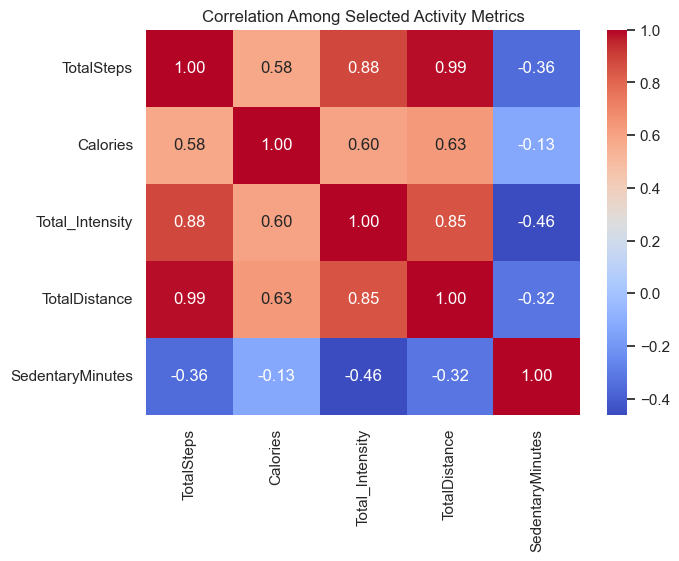

In [142]:
corr_cols = ['TotalSteps', 'Calories', 'Total_Intensity', 'TotalDistance', 'SedentaryMinutes']
plt.figure(figsize=(7,5))
sns.heatmap(df_fitbit[corr_cols].corr(), annot = True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Among Selected Activity Metrics')
plt.show()

# Wrangle the Data

In [143]:
print(df_fitbit.isna().sum())

Id                            0
ActivityDate                  0
TotalSteps                    0
TotalDistance                 0
TrackerDistance               0
LoggedActivitiesDistance      0
VeryActiveDistance            0
ModeratelyActiveDistance      0
LightActiveDistance           0
SedentaryActiveDistance       0
VeryActiveMinutes             0
FairlyActiveMinutes           0
LightlyActiveMinutes          0
SedentaryMinutes              0
Calories                      0
Sleep_Day                   963
Total_Sleep_Records         963
Total_Minutes_Asleep        963
Total_Time_In_Bed           963
date                         31
Total_Intensity              31
Average_Intensity            31
dtype: int64


In [144]:
avg_Total_Intensity = df_fitbit['Total_Intensity'].astype('float').mean(axis=0)
print("Average:", avg_Total_Intensity)

Average: 278.78241430700444


In [145]:
df_fitbit['Total_Intensity']=df_fitbit['Total_Intensity'].replace(np.nan, avg_Total_Intensity)

In [146]:
print("Average:", avg_Total_Intensity)

Average: 278.78241430700444


In [147]:
print(df_fitbit.isna().sum())

Id                            0
ActivityDate                  0
TotalSteps                    0
TotalDistance                 0
TrackerDistance               0
LoggedActivitiesDistance      0
VeryActiveDistance            0
ModeratelyActiveDistance      0
LightActiveDistance           0
SedentaryActiveDistance       0
VeryActiveMinutes             0
FairlyActiveMinutes           0
LightlyActiveMinutes          0
SedentaryMinutes              0
Calories                      0
Sleep_Day                   963
Total_Sleep_Records         963
Total_Minutes_Asleep        963
Total_Time_In_Bed           963
date                         31
Total_Intensity               0
Average_Intensity            31
dtype: int64


In [148]:
Intensity_average = df_fitbit['Average_Intensity'].astype('float').mean(axis=0)
print("Average:", Intensity_average)

Average: 0.19527236549018379


In [149]:
df_fitbit['Average_Intensity']=df_fitbit['Average_Intensity'].replace(np.nan, Intensity_average)

In [150]:
df_fitbit.describe()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,...,LightlyActiveMinutes,SedentaryMinutes,Calories,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed,date,Total_Intensity,Average_Intensity
count,1.373000e+03,1373,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,...,1373.000000,1373.000000,1373.000000,410,410.000000,410.000000,410.000000,1342,1373.000000,1373.000000
mean,4.782326e+09,2016-04-19 04:24:17.829570304,7377.375091,5.289031,5.261930,0.128591,1.413146,0.546052,3.238128,0.001733,...,188.096140,1001.346686,2294.812090,2016-04-26 11:38:55.609756160,1.119512,419.173171,458.482927,2016-04-19 09:13:40.864381440,278.782414,0.195272
min,1.503960e+09,2016-03-12 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,2016-04-12 00:00:00,1.000000,58.000000,61.000000,2016-03-12 00:00:00,0.000000,0.000000
25%,2.320127e+09,2016-04-08 00:00:00,3321.000000,2.280000,2.270000,0.000000,0.000000,0.000000,1.730000,0.000000,...,117.000000,734.000000,1820.000000,2016-04-19 00:00:00,1.000000,361.000000,403.750000,2016-04-09 00:00:00,156.000000,0.111458
50%,4.445115e+09,2016-04-19 00:00:00,7142.000000,5.030000,5.020000,0.000000,0.120000,0.200000,3.280000,0.000000,...,196.000000,1062.000000,2129.000000,2016-04-27 00:00:00,1.000000,432.500000,463.000000,2016-04-20 00:00:00,286.000000,0.200694
75%,6.962181e+09,2016-04-30 00:00:00,10645.000000,7.570000,7.570000,0.000000,1.860000,0.780000,4.710000,0.000000,...,263.000000,1246.000000,2781.000000,2016-05-04 00:00:00,1.000000,490.000000,526.000000,2016-04-30 00:00:00,395.000000,0.275000
max,8.877689e+09,2016-05-12 00:00:00,36019.000000,28.030001,28.030001,6.727057,21.920000,6.480000,12.510000,0.110000,...,720.000000,1440.000000,4900.000000,2016-05-12 00:00:00,3.000000,796.000000,961.000000,2016-05-12 00:00:00,904.000000,0.627778
std,2.381544e+09,NaN,5198.133424,3.987341,3.973439,0.695630,2.622729,0.872581,2.104300,0.007800,...,113.095058,304.168197,725.526989,NaN,0.346636,118.635918,127.455140,NaN,167.210074,0.115805


In [151]:
df_fitbit = df_fitbit.drop(columns=['date','Sleep_Day','TrackerDistance'])

In [152]:
df_fitbit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Id                        1373 non-null   int64         
 1   ActivityDate              1373 non-null   datetime64[ns]
 2   TotalSteps                1373 non-null   int64         
 3   TotalDistance             1373 non-null   float64       
 4   LoggedActivitiesDistance  1373 non-null   float64       
 5   VeryActiveDistance        1373 non-null   float64       
 6   ModeratelyActiveDistance  1373 non-null   float64       
 7   LightActiveDistance       1373 non-null   float64       
 8   SedentaryActiveDistance   1373 non-null   float64       
 9   VeryActiveMinutes         1373 non-null   int64         
 10  FairlyActiveMinutes       1373 non-null   int64         
 11  LightlyActiveMinutes      1373 non-null   int64         
 12  SedentaryMinutes    

In [153]:
print(df_fitbit.isna().sum())

Id                            0
ActivityDate                  0
TotalSteps                    0
TotalDistance                 0
LoggedActivitiesDistance      0
VeryActiveDistance            0
ModeratelyActiveDistance      0
LightActiveDistance           0
SedentaryActiveDistance       0
VeryActiveMinutes             0
FairlyActiveMinutes           0
LightlyActiveMinutes          0
SedentaryMinutes              0
Calories                      0
Total_Sleep_Records         963
Total_Minutes_Asleep        963
Total_Time_In_Bed           963
Total_Intensity               0
Average_Intensity             0
dtype: int64


In [154]:
df_fitbit['has_sleep_data'] = df_fitbit['Total_Minutes_Asleep'].notna().astype(int)

In [155]:
sleep_subset = df_fitbit[df_fitbit['has_sleep_data'] == 1]

In [156]:
print(df_fitbit.isna().sum())

Id                            0
ActivityDate                  0
TotalSteps                    0
TotalDistance                 0
LoggedActivitiesDistance      0
VeryActiveDistance            0
ModeratelyActiveDistance      0
LightActiveDistance           0
SedentaryActiveDistance       0
VeryActiveMinutes             0
FairlyActiveMinutes           0
LightlyActiveMinutes          0
SedentaryMinutes              0
Calories                      0
Total_Sleep_Records         963
Total_Minutes_Asleep        963
Total_Time_In_Bed           963
Total_Intensity               0
Average_Intensity             0
has_sleep_data                0
dtype: int64


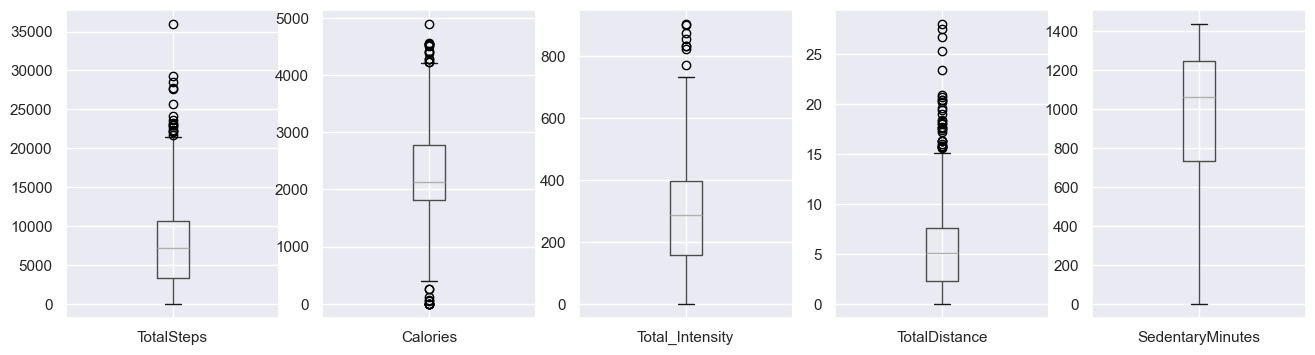

In [157]:
predictors = ['TotalSteps','Calories', 'Total_Intensity', 'TotalDistance', 'SedentaryMinutes']
fig, axes = plt.subplots(1, len(predictors), figsize=(16,4))
for ax, col in zip(axes, predictors):
    df_fitbit.boxplot(column=col, ax=ax)

In [158]:
for col in predictors:
    Q1 = df_fitbit[col].quantile(0.25)
    Q3 = df_fitbit[col].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((df_fitbit[col] < lower) | (df_fitbit[col]>upper)).sum()
    print(f"{col}: {outlier_count} outliers (bounds: {lower:.1f} to {upper:.1f})")

TotalSteps: 16 outliers (bounds: -7665.0 to 21631.0)
Calories: 25 outliers (bounds: 378.5 to 4222.5)
Total_Intensity: 8 outliers (bounds: -202.5 to 753.5)
TotalDistance: 31 outliers (bounds: -5.7 to 15.5)
SedentaryMinutes: 0 outliers (bounds: -34.0 to 2014.0)


**Interpretation**
- TotalSteps: A few high outliers - represent high achievement days
- Calories: High and low outliers - represent high and low achievement days
- Total_Intensity: A few high outliers - represent high achievement days
- Total_Minutes_Asleep: More lower outliers - potential signal for recovery signal
- Sedentary Minutes - No outliers

In [159]:
df_fitbit['TotalActiveDistance'] = (
    df_fitbit['VeryActiveDistance'] +
    df_fitbit['ModeratelyActiveDistance']+
    df_fitbit['LightActiveDistance']
)
print (df_fitbit['TotalActiveDistance'].describe())

count    1373.000000
mean        5.197327
std         4.013624
min         0.000000
25%         2.090000
50%         4.940000
75%         7.510000
max        28.020000
Name: TotalActiveDistance, dtype: float64


In [160]:
df_fitbit['achievement_score'] = df_fitbit['Calories']

### Feature Engineering

TotalActiveDistance is calculated by combining very active, moderately active, and lightly active distance.

The achievement_score is defined as daily calories burned. This renamed outcome is used to make the exploratory analysis easier to discuss consistently throughout the notebook. It should not be interpreted as a clinical measure of fitness, burnout, or personal achievement.

# Preliminary Feature and Modeling Exploration

The following models explore relationships among the available Fitbit variables. The primary outcome, achievement_score, represents calories burned.

These models do not directly predict burnout because the dataset does not contain a burnout outcome. Instead, they help identify relationships and features that may support future burnout-risk modeling.

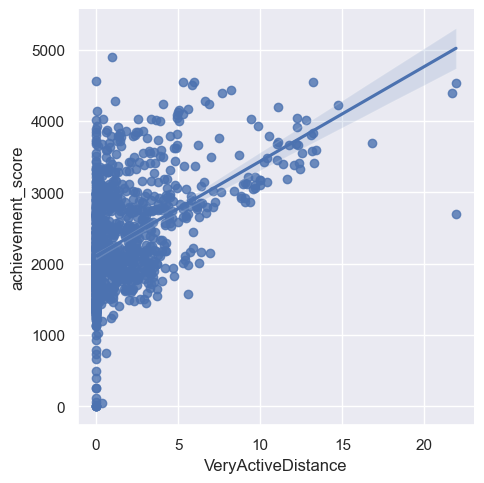

In [161]:
# Linear relationship between very active distance and achievement score
sns.lmplot(data=df_fitbit, x='VeryActiveDistance', y='achievement_score')
plt.show()

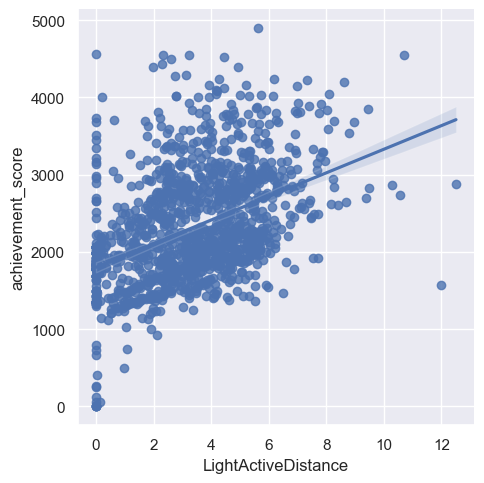

In [162]:
# Linear relationship between light active distance and achievement score
sns.lmplot(data=df_fitbit, x='LightActiveDistance', y='achievement_score')
plt.show()

#### Total Active Distance (Cumulative Movement)

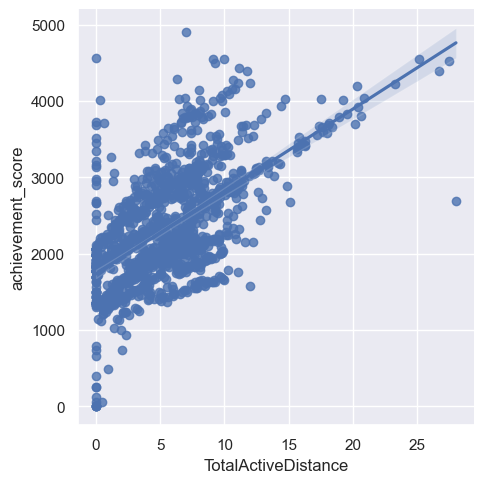

In [163]:
# Linear relationship between total active distance and achievement score
sns.lmplot(data=df_fitbit, x='TotalActiveDistance', y='achievement_score')
plt.show()

### Feature Engineering

TotalActiveDistance combines very active, moderately active, and lightly active distance into one measure of total movement-related distance.

Calories are retained as an exploratory outcome for evaluating whether the activity features behave as expected. Calories are not treated as a burnout measure.

#### Sleep

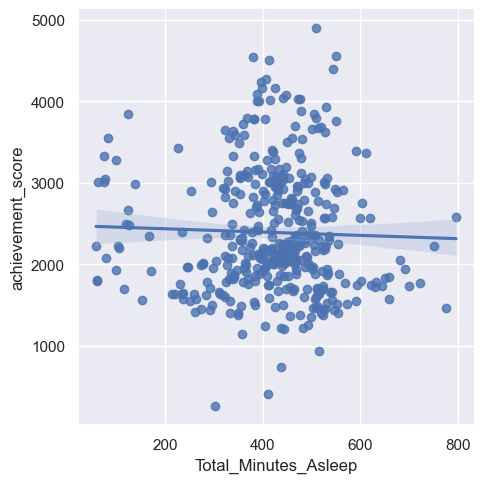

In [164]:
# Linear relationship between sleep duration and achievement score
sns.lmplot(data=df_fitbit, x='Total_Minutes_Asleep', y='achievement_score')
plt.show()

The scatterplot does not show a strong linear relationship between sleep duration and achievement score among records with available sleep data. However, sleep is missing for many participant-days, so this result should be interpreted cautiously.

A future analysis could examine whether prior-night sleep predicts activity or achievement on the following day.

In [165]:
# Simple Linear Regression of Achievement Score and Total Active Score 
x = df_fitbit[['TotalActiveDistance']]
y = df_fitbit['achievement_score']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Coefficient:", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))
print("R²:", round(r2, 3))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

Coefficient: 111.48
Intercept: 1711.49
R²: 0.306
MAE: 442.97
RMSE: 572.11


This regression examines whether total active distance is associated with the achievement score. It is an exploratory calorie-prediction model and should not be interpreted as a burnout model.

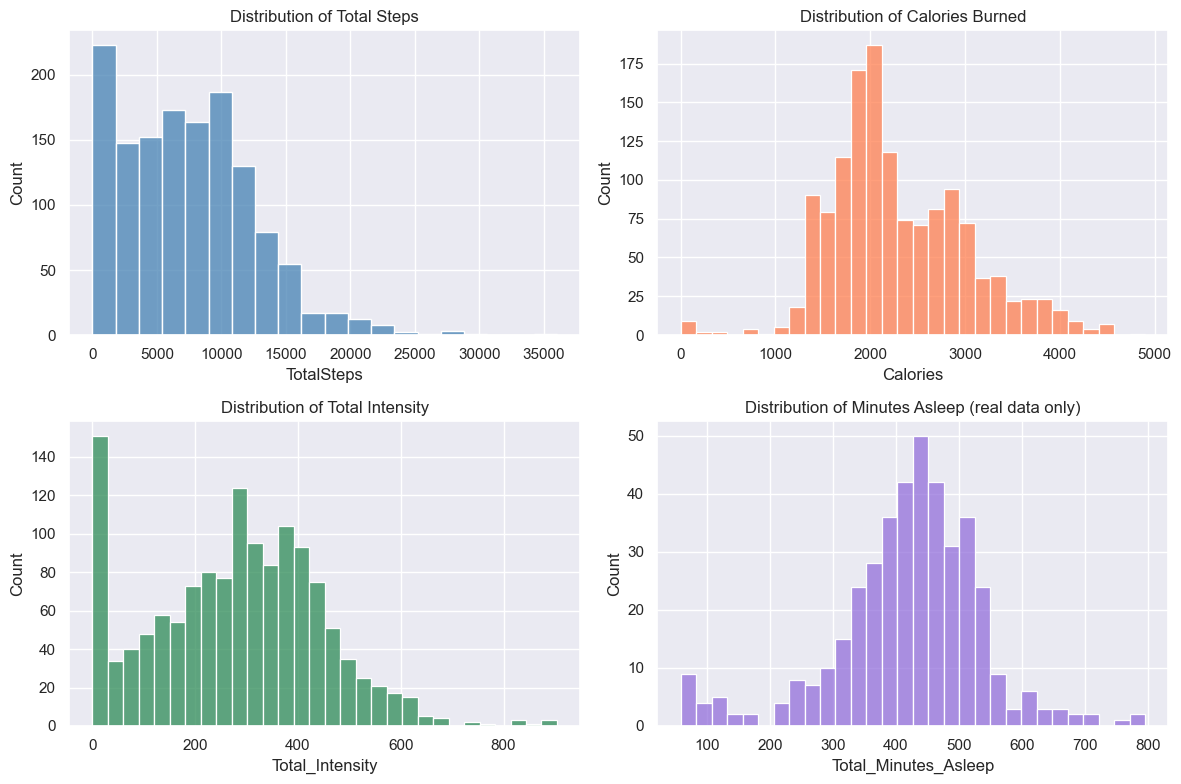

In [166]:
fig, axes = plt.subplots(2,2,figsize=(12,8))

sns.histplot(df_fitbit['TotalSteps'], bins=20, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribution of Total Steps')

sns.histplot(df_fitbit['Calories'], bins=30, ax=axes[0,1], color='coral')
axes[0,1].set_title('Distribution of Calories Burned')

sns.histplot(df_fitbit['Total_Intensity'], bins=30, ax=axes[1,0], color='seagreen')
axes[1,0].set_title('Distribution of Total Intensity')

sns.histplot(df_fitbit[df_fitbit['has_sleep_data']==1]['Total_Minutes_Asleep'], bins=30, ax=axes[1,1], color='mediumpurple')
axes[1,1].set_title('Distribution of Minutes Asleep (real data only)')

plt.tight_layout()
plt.show()

In [167]:
min_val = df_fitbit['TotalActiveDistance'].min()
max_val = df_fitbit['TotalActiveDistance'].max()

distance_bins = np.linspace(min_val, max_val, 5)
#distance_bins = [0,2.09,4.94,7.51, float('inf')]
distance_labels = ['Low', 'Moderate', 'High', 'Very High']

df_fitbit['active_distance_tier'] = pd.cut(df_fitbit['TotalActiveDistance'], bins=distance_bins, labels=distance_labels, include_lowest=True)
print(df_fitbit['active_distance_tier'].value_counts())

active_distance_tier
Low          956
Moderate     380
High          32
Very High      5
Name: count, dtype: int64


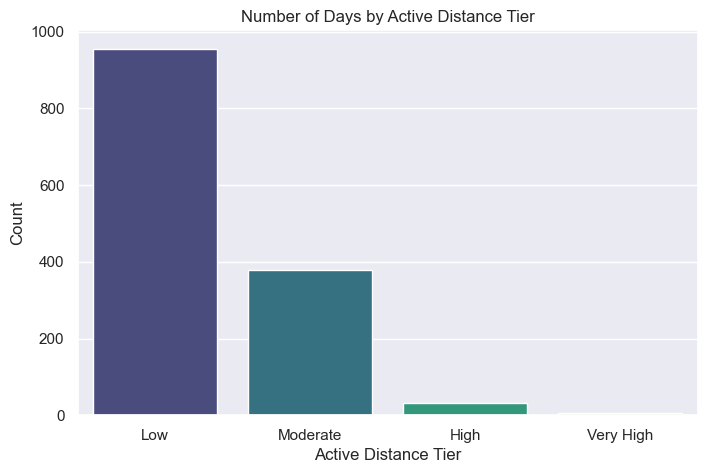

In [168]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_fitbit, x='active_distance_tier', order=distance_labels, hue='active_distance_tier', palette='viridis', legend=False)
plt.title('Number of Days by Active Distance Tier')
plt.xlabel('Active Distance Tier')
plt.ylabel('Count')
plt.show()

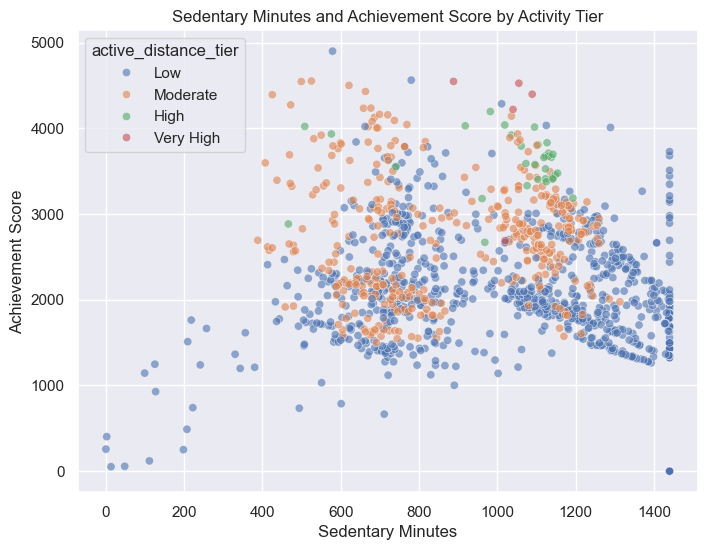

In [169]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_fitbit,
    x='SedentaryMinutes',
    y='Calories',
    hue='active_distance_tier',
    alpha=0.6
)

plt.title('Sedentary Minutes and Achievement Score by Activity Tier')
plt.xlabel('Sedentary Minutes')
plt.ylabel('Achievement Score')
plt.show()

In [170]:
features = ['VeryActiveMinutes','FairlyActiveMinutes', 'LightlyActiveMinutes',
            'SedentaryMinutes','Total_Intensity', 'TotalActiveDistance']

model_df = df_fitbit.dropna(subset=features + ['achievement_score'])

x = model_df[features]
y = model_df['achievement_score']

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=200, random_state=43)
rf.fit(x_train, y_train)

y_pred = rf.predict(x_test)
print("R^2", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature Importances:")
print(importance)

R^2 0.5254246705354443
MAE: 339.40538013134534

Feature Importances:
VeryActiveMinutes       0.393784
TotalActiveDistance     0.226522
SedentaryMinutes        0.127983
Total_Intensity         0.111346
FairlyActiveMinutes     0.071212
LightlyActiveMinutes    0.069152
dtype: float64


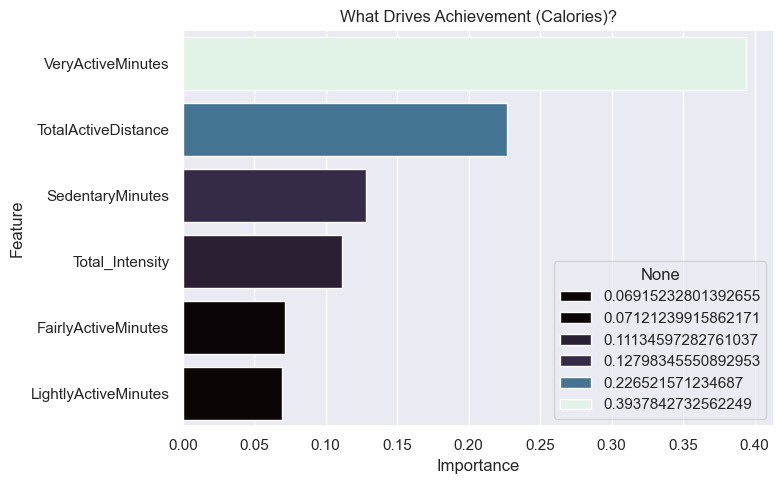

In [171]:
plt.figure(figsize=(8,5))
sns.barplot(x=importance.values, y=importance.index, hue=importance, palette='mako')
plt.title('What Drives Achievement (Calories)?')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

The random forest model evaluates which activity variables are most useful for predicting the achievement score. Very active minutes and total active distance are among the most important predictors.

Because the achievement score is based on calories, these findings describe calorie expenditure rather than burnout risk.

In [172]:
user_consistency = df_fitbit.groupby('Id')['TotalSteps'].agg(['mean','std']).reset_index()
user_consistency['cv_steps'] = user_consistency['std']/user_consistency['mean']

consistency_features = ['VeryActiveMinutes', 'FairlyActiveMinutes', 'Total_Intensity', 'TotalActiveDistance']
user_features = df_fitbit.groupby('Id')[consistency_features].mean().reset_index()

consistency_df = user_consistency.merge(user_features, on='Id')

x2 = consistency_df[consistency_features]
y2 = consistency_df['cv_steps']

rf2 = RandomForestRegressor(n_estimators=200, random_state=42)
rf2.fit(x2,y2)

importances2 =pd.Series(rf2.feature_importances_, index=consistency_features).sort_values(ascending=False)
print("Consistency Feature Importances (only 35 users - interpret cautiously):")
print(importances2)

Consistency Feature Importances (only 35 users - interpret cautiously):
TotalActiveDistance    0.519616
Total_Intensity        0.378764
FairlyActiveMinutes    0.053656
VeryActiveMinutes      0.047964
dtype: float64


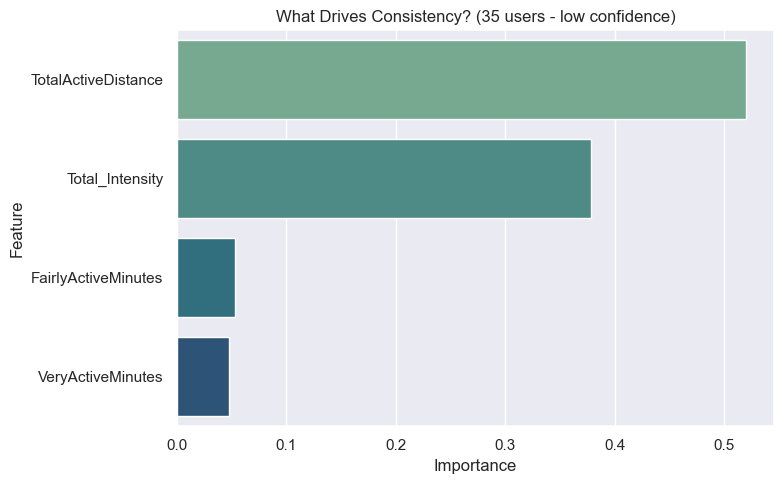

In [173]:
plt.figure(figsize=(8,5))
sns.barplot(x=importances2.values, y=importances2.index, palette='crest')
plt.title("What Drives Consistency? (35 users - low confidence)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
          

In [174]:
features = ['VeryActiveMinutes', 'FairlyActiveMinutes', 'LightlyActiveMinutes','Total_Intensity']

clf_df = df_fitbit.dropna(subset=features + ['active_distance_tier'])

x = clf_df[features]
y = clf_df['active_distance_tier']

x_train, x_test, y_train, y_test =train_test_split(x, y, test_size=0.25, random_state=42,stratify=y)

dep = np.arange(1,9)
train_accuracy = np.empty(len(dep))
test_accuracy = np.empty(len(dep))

for i, k in enumerate(dep):
    clf = tree.DecisionTreeClassifier(max_depth=k, random_state=42)
    clf.fit(x_train, y_train)

    train_accuracy[i] = clf.score(x_train, y_train)
    test_accuracy[i] = clf.score(x_test, y_test)
    

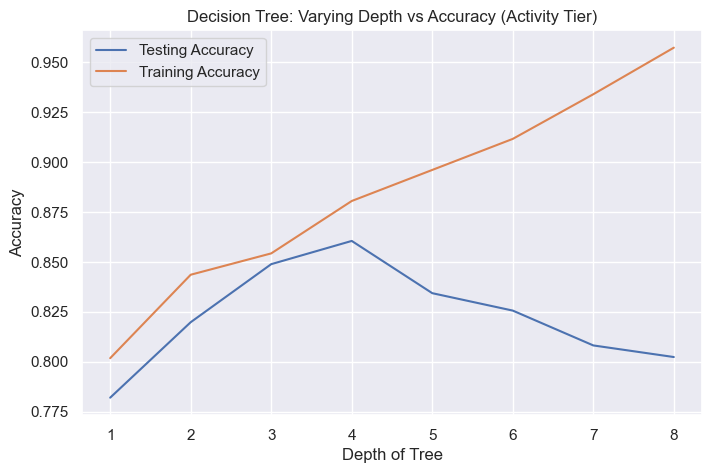

In [175]:
plt.figure(figsize=(8,5))
plt.title('Decision Tree: Varying Depth vs Accuracy (Activity Tier)')
plt.plot(dep, test_accuracy, label='Testing Accuracy')
plt.plot(dep, train_accuracy, label ='Training Accuracy')
plt.legend()
plt.xlabel('Depth of Tree')
plt.ylabel('Accuracy')
plt.show()

In [176]:
best_depth = dep[np.argmax(test_accuracy)]

print(
    f"Best depth based on highest test accuracy: {best_depth}"
)

final_tree = tree.DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

final_tree.fit(x_train, y_train)

print(
    "Training accuracy:",
    round(final_tree.score(x_train, y_train), 3)
)

print(
    "Testing accuracy:",
    round(final_tree.score(x_test, y_test), 3)
)

Best depth based on highest test accuracy: 4
Training accuracy: 0.88
Testing accuracy: 0.86


The decision tree predicts activity-distance tiers using active minutes and total intensity. It does not predict burnout. The activity tiers are derived from movement distance, so the results should be viewed as exploratory.

# Conclusion and Next Steps

This notebook combined daily activity, hourly intensity, and available sleep information into one participant-day dataset. The analysis examined data quality, missing information, variable distributions, correlations, activity tiers, achievement score, and participant consistency.

The preliminary models show that activity measures such as active minutes, intensity, and active distance contain useful information for predicting the achievement score. However, none of the current models directly predicts burnout.

The next phase should define a measurable behavioral burnout-risk target based on sustained participant-specific declines in activity. Rolling activity averages, prior-night sleep, recent intensity, and changes in sedentary behavior could then be evaluated as predictors. A participant-level or time-based train/test split should be used to avoid mixing records from the same participants across training and testing data.